# EDA

## Introduction
This notebook explores the Bank Marketing dataset to understand its structure, key patterns, and relationships before cleaning and preprocessing is applied. The goal is to examine distributions, identify potential outliers, assess categorical variables, and evaluate the target imbalance. 

These insights are going to guide the data cleaning and preprocessing decisions in the next stage and help shape the modelling strategy.

In [2]:
#Import the required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
#Read in csv
df = pd.read_csv('../01_data/bank-full.csv', sep = ';')
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Distribution Visualisations

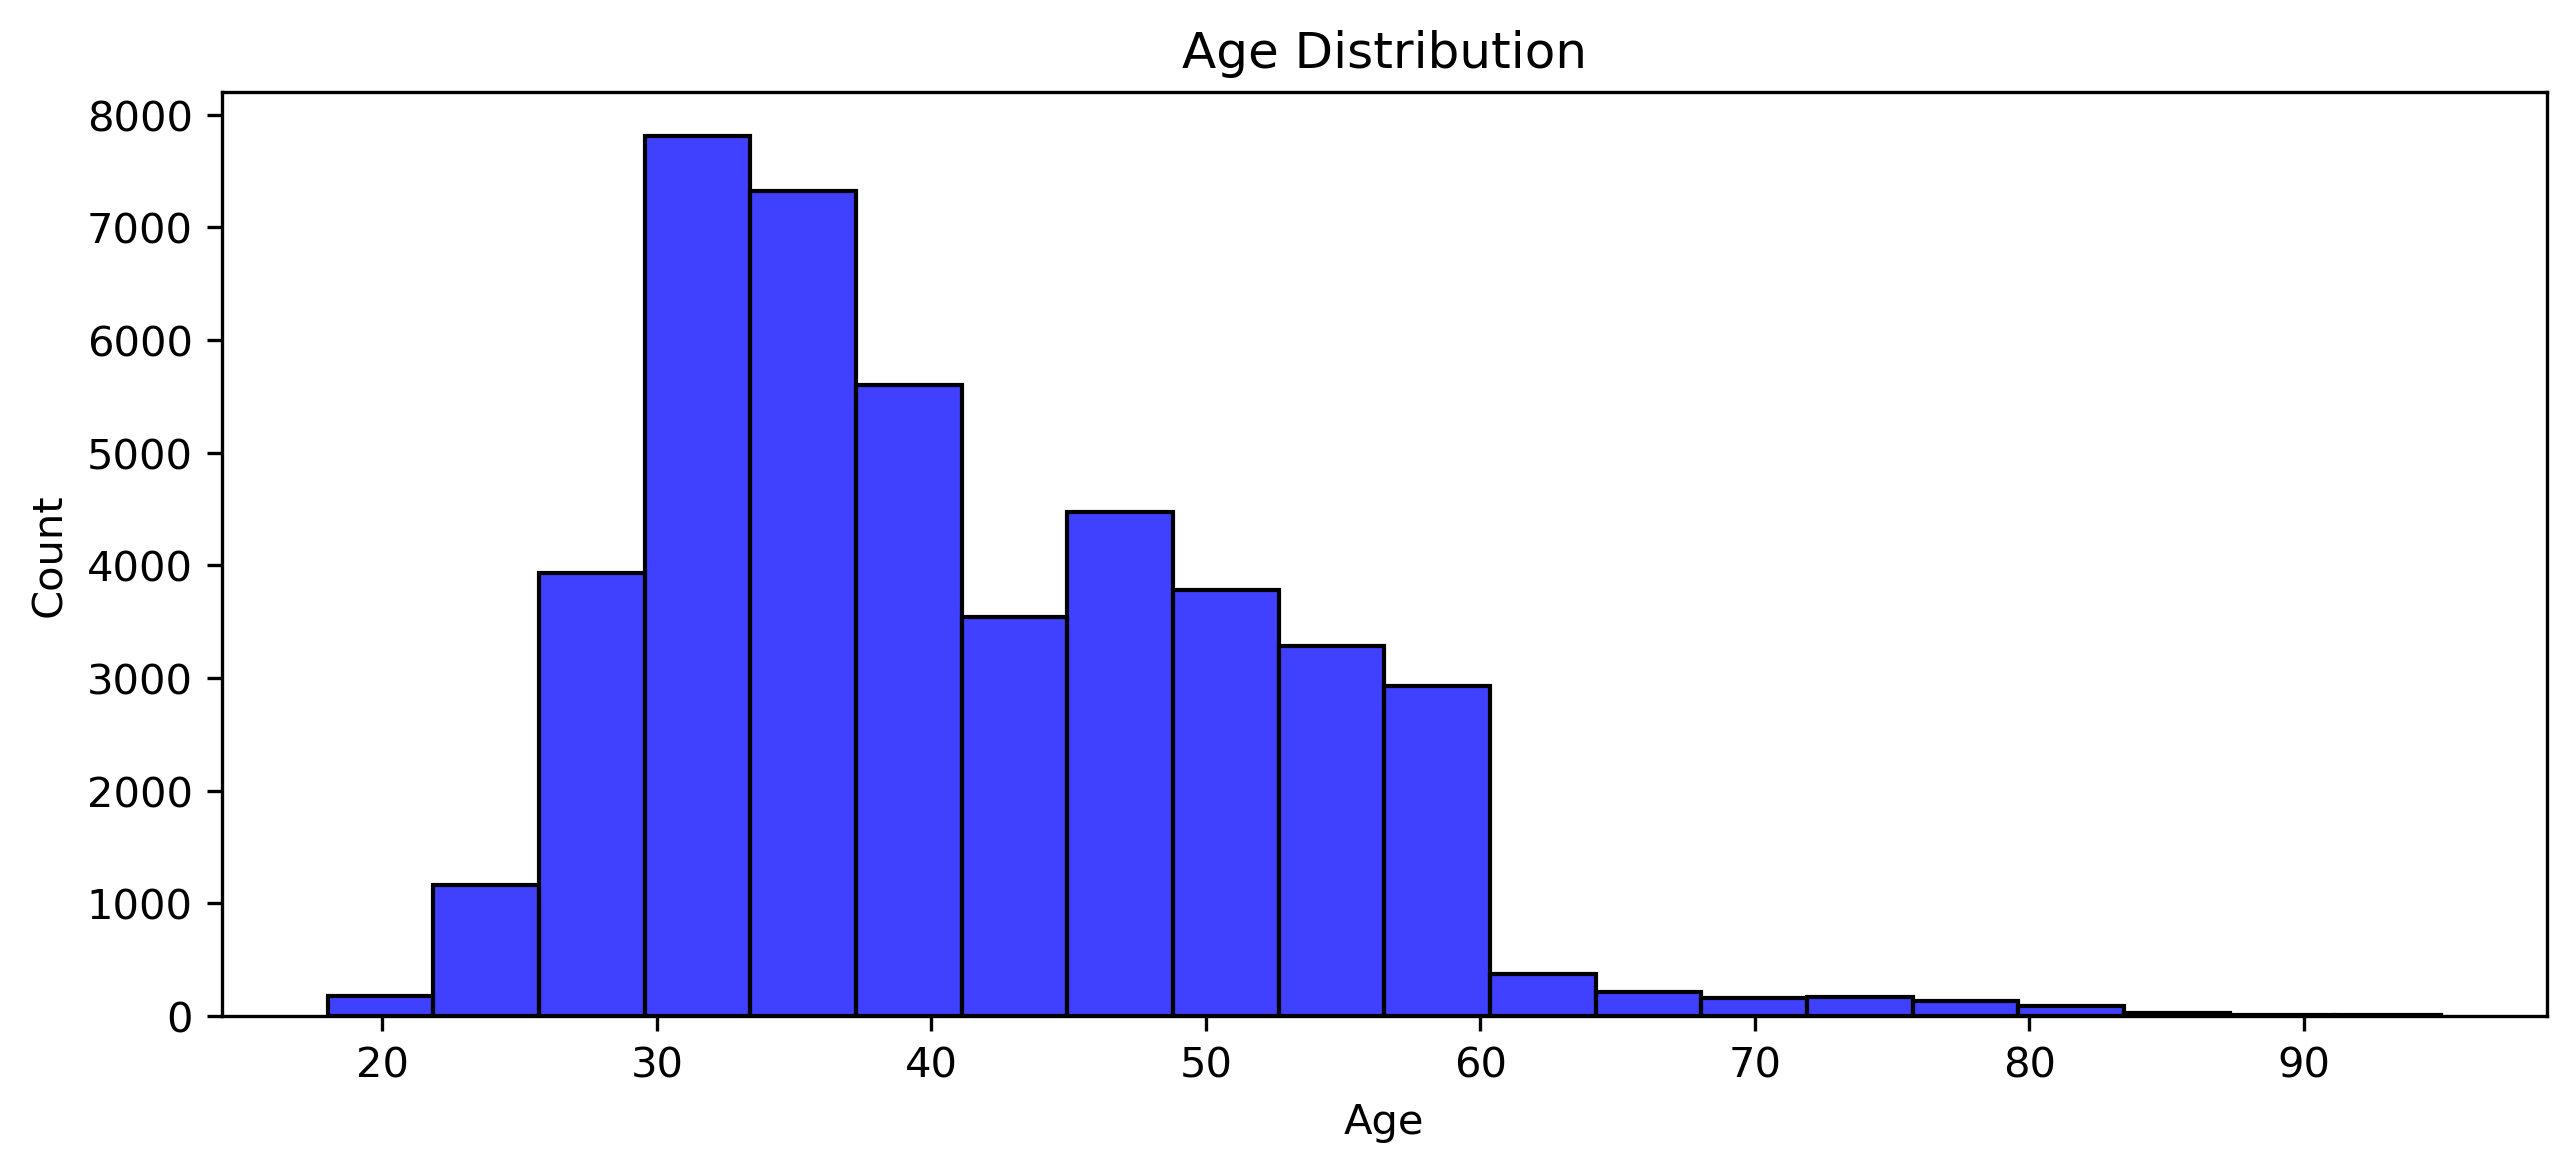

In [36]:
#AGE DISTRIBUTION
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'age', bins = 20, color = 'blue')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.show()

**Commentary:**
* The age distribution is moderately right-skewed, most customers are concentrated between 30 and 40 years old.
* There are fewer younger customers and a gradual decline in older age groups.
* This suggests the marketing campaign primarily reached working-age adults, which may influence how age interacts with other features.

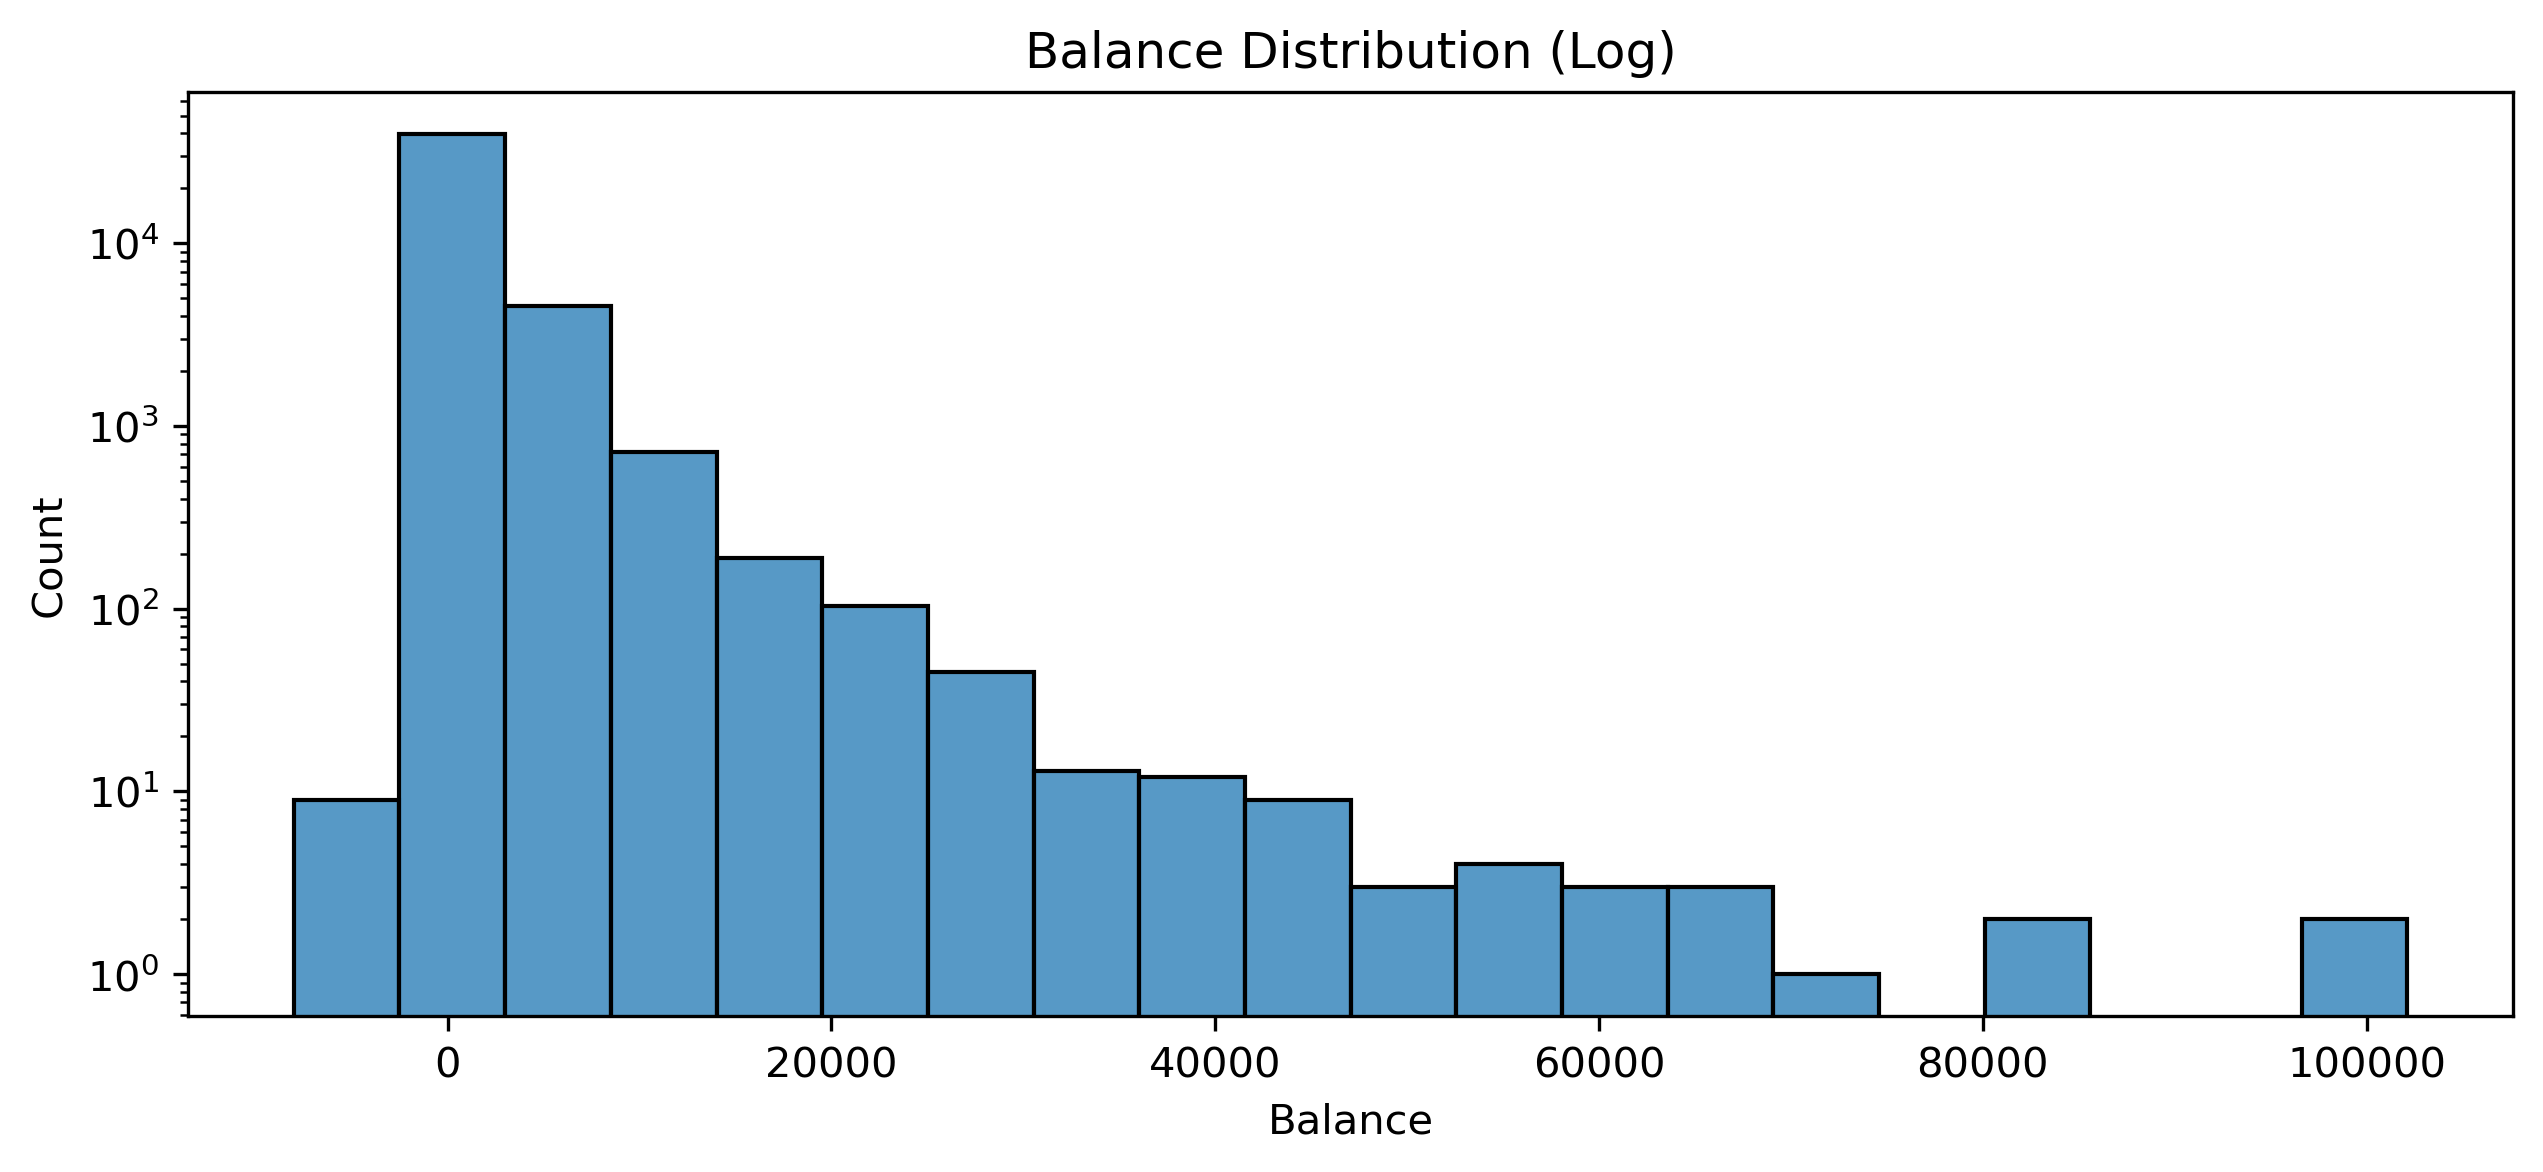

In [37]:
#BALANCE DISTRIBUTION
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'balance', bins = 20, log = True)

plt.title('Balance Distribution (Log)')
plt.xlabel('Balance')
plt.show()

**Commentary:**
* The balance variable is heavily right-skewed. Most customers have lower yearly balances, typically between 0 and 2,000.
* A small minority have negative balances, suggesting overdrafts.
* As balance increases, the number of customers declines sharply, with only a few individuals holing very high balances (80,000-100,000).
* The extreme values seem to be genuine and reflect natural variation in customer wealth rather than data errors.

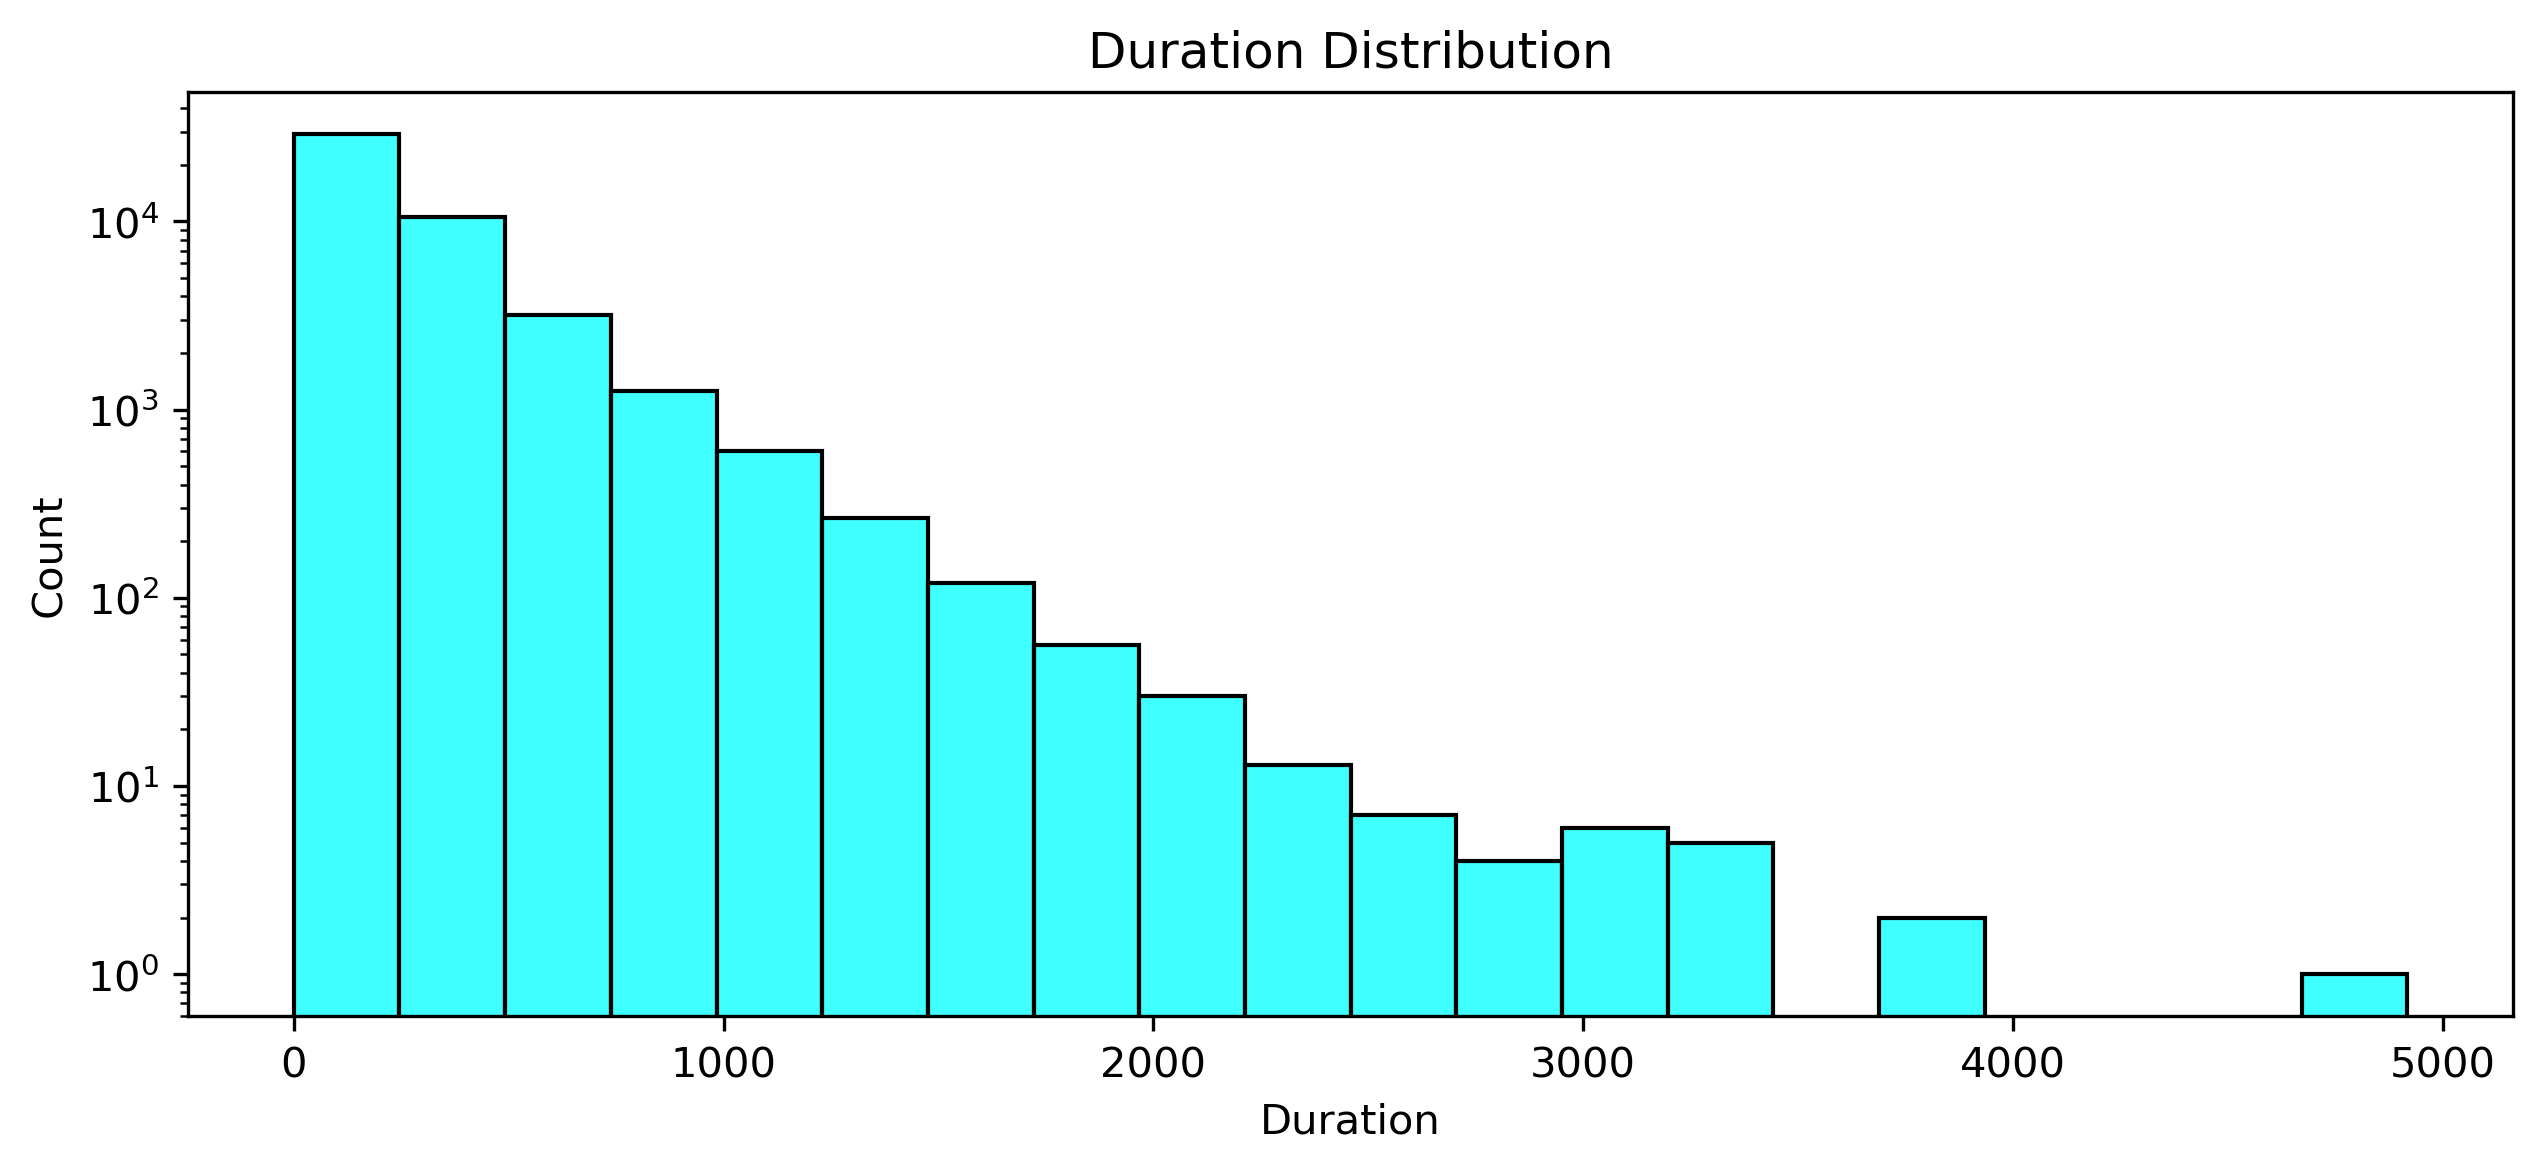

In [75]:
#DURATION DISTRIBUTION
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'duration', bins = 20, log = True, color = 'cyan')

plt.title('Duration Distribution')
plt.xlabel('Duration')
plt.show()

**Commentary:**
* The duration variable is right-skewed with the vast majority of calls being very short.
* Counts drop sharply as duration increases.
* Only a small number of calls lasts several minutes, and a few extend beyond 4,000-5,000 seconds.
* This reflect natural call behaviour where most customers disengae quickly, and a minority remain on the call for extended periods.

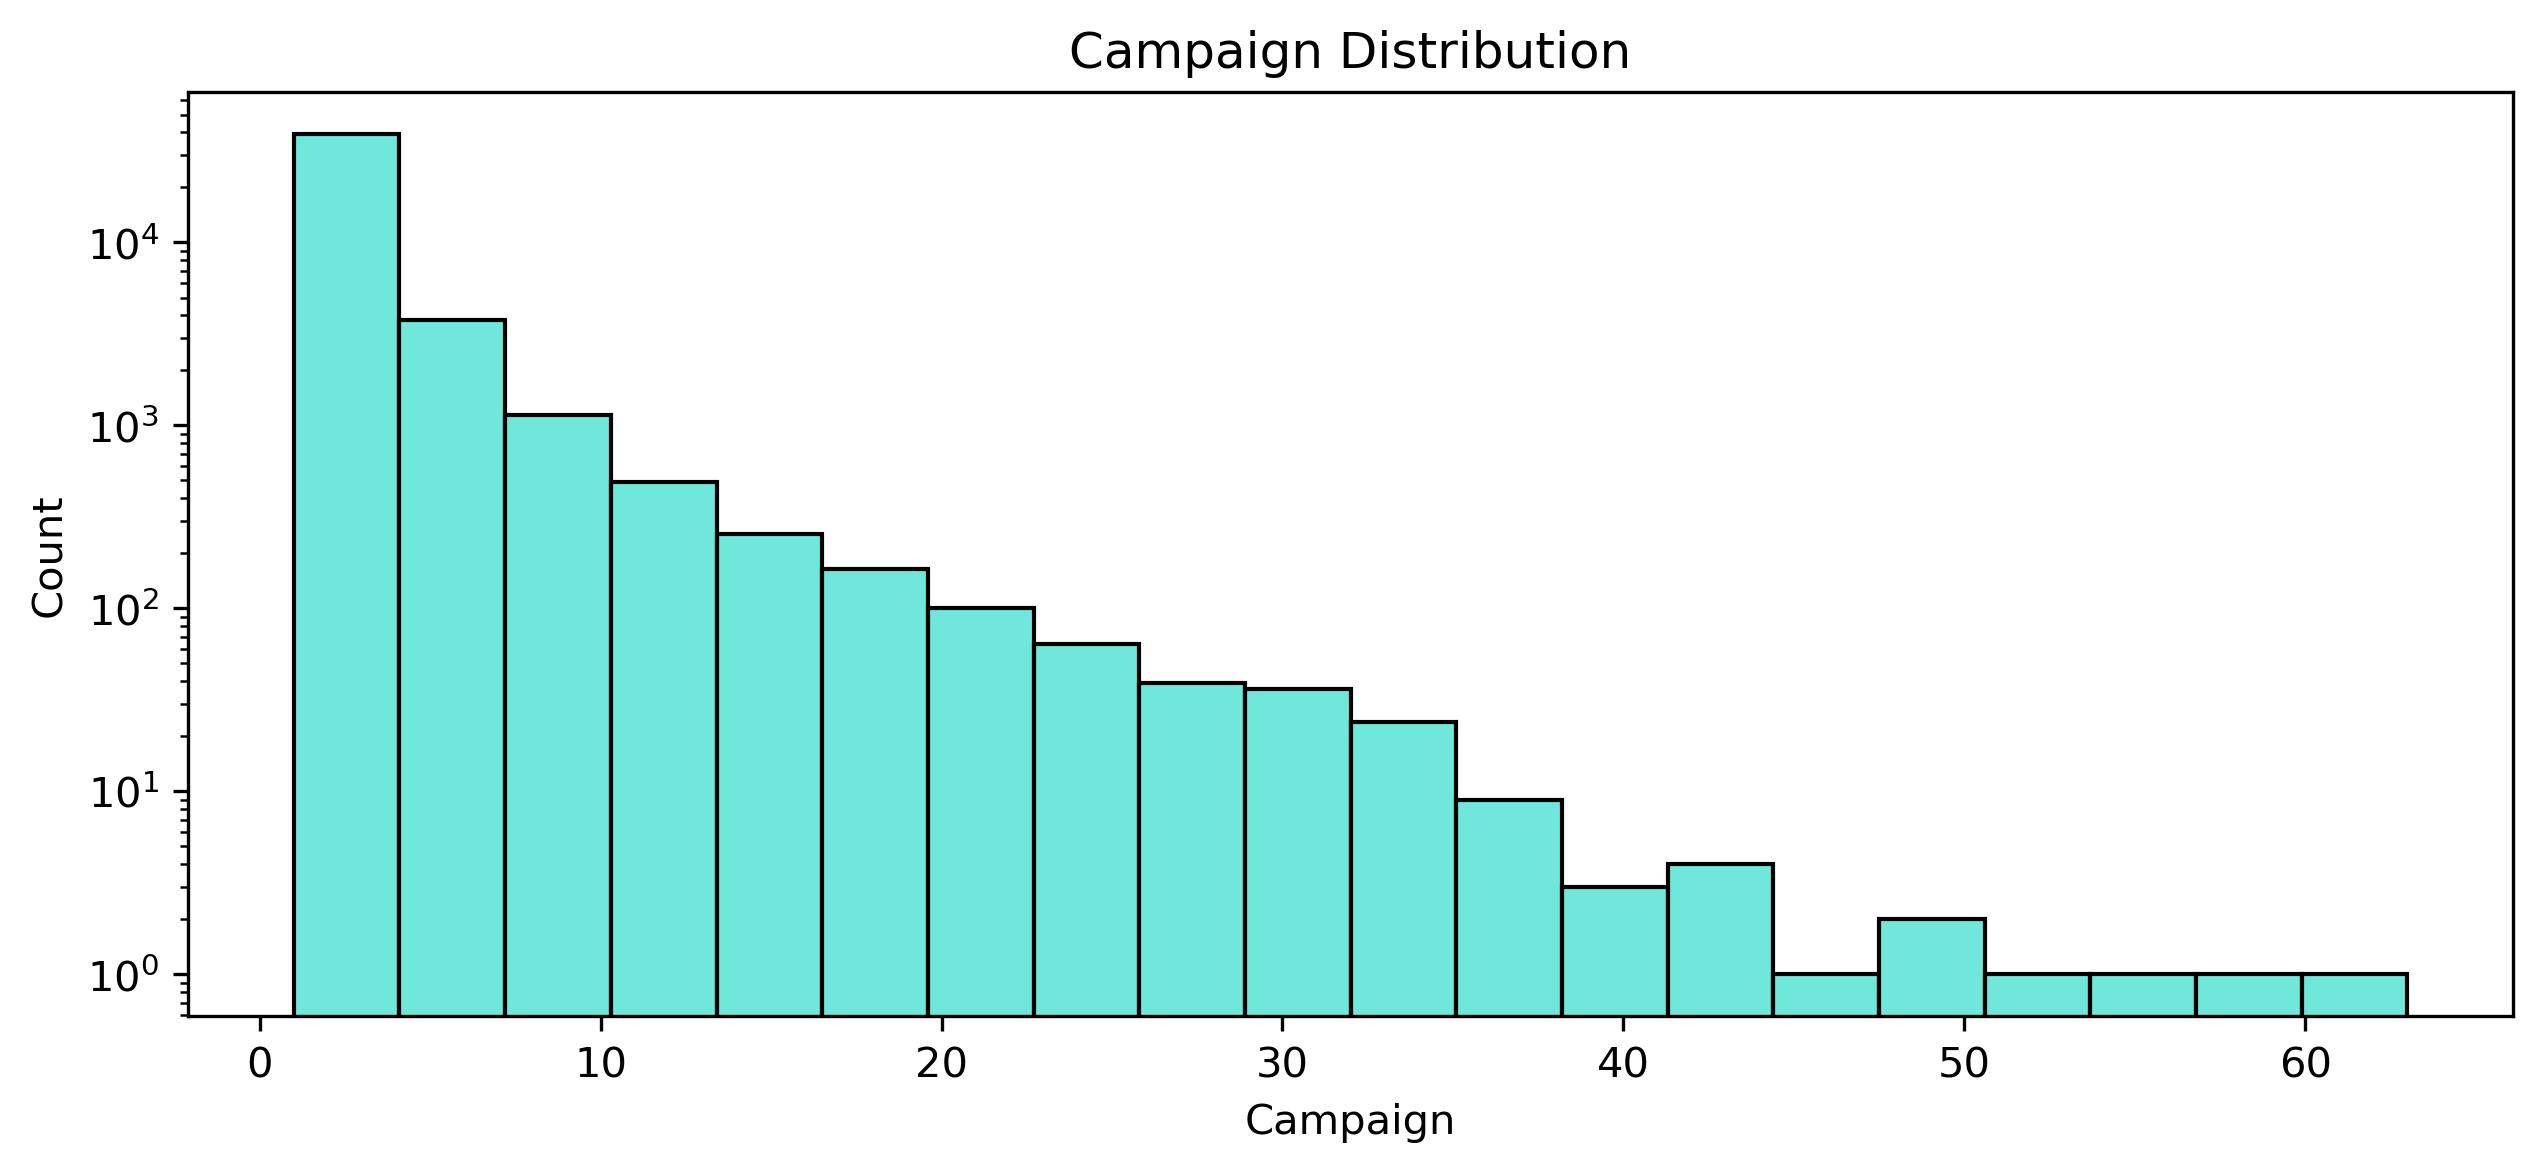

In [8]:
#CAMPAIGN DISTRIBUTION
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'campaign', bins = 20, log = True, color = 'turquoise')

plt.title('Campaign Distribution')
plt.xlabel('Campaign')
plt.show()

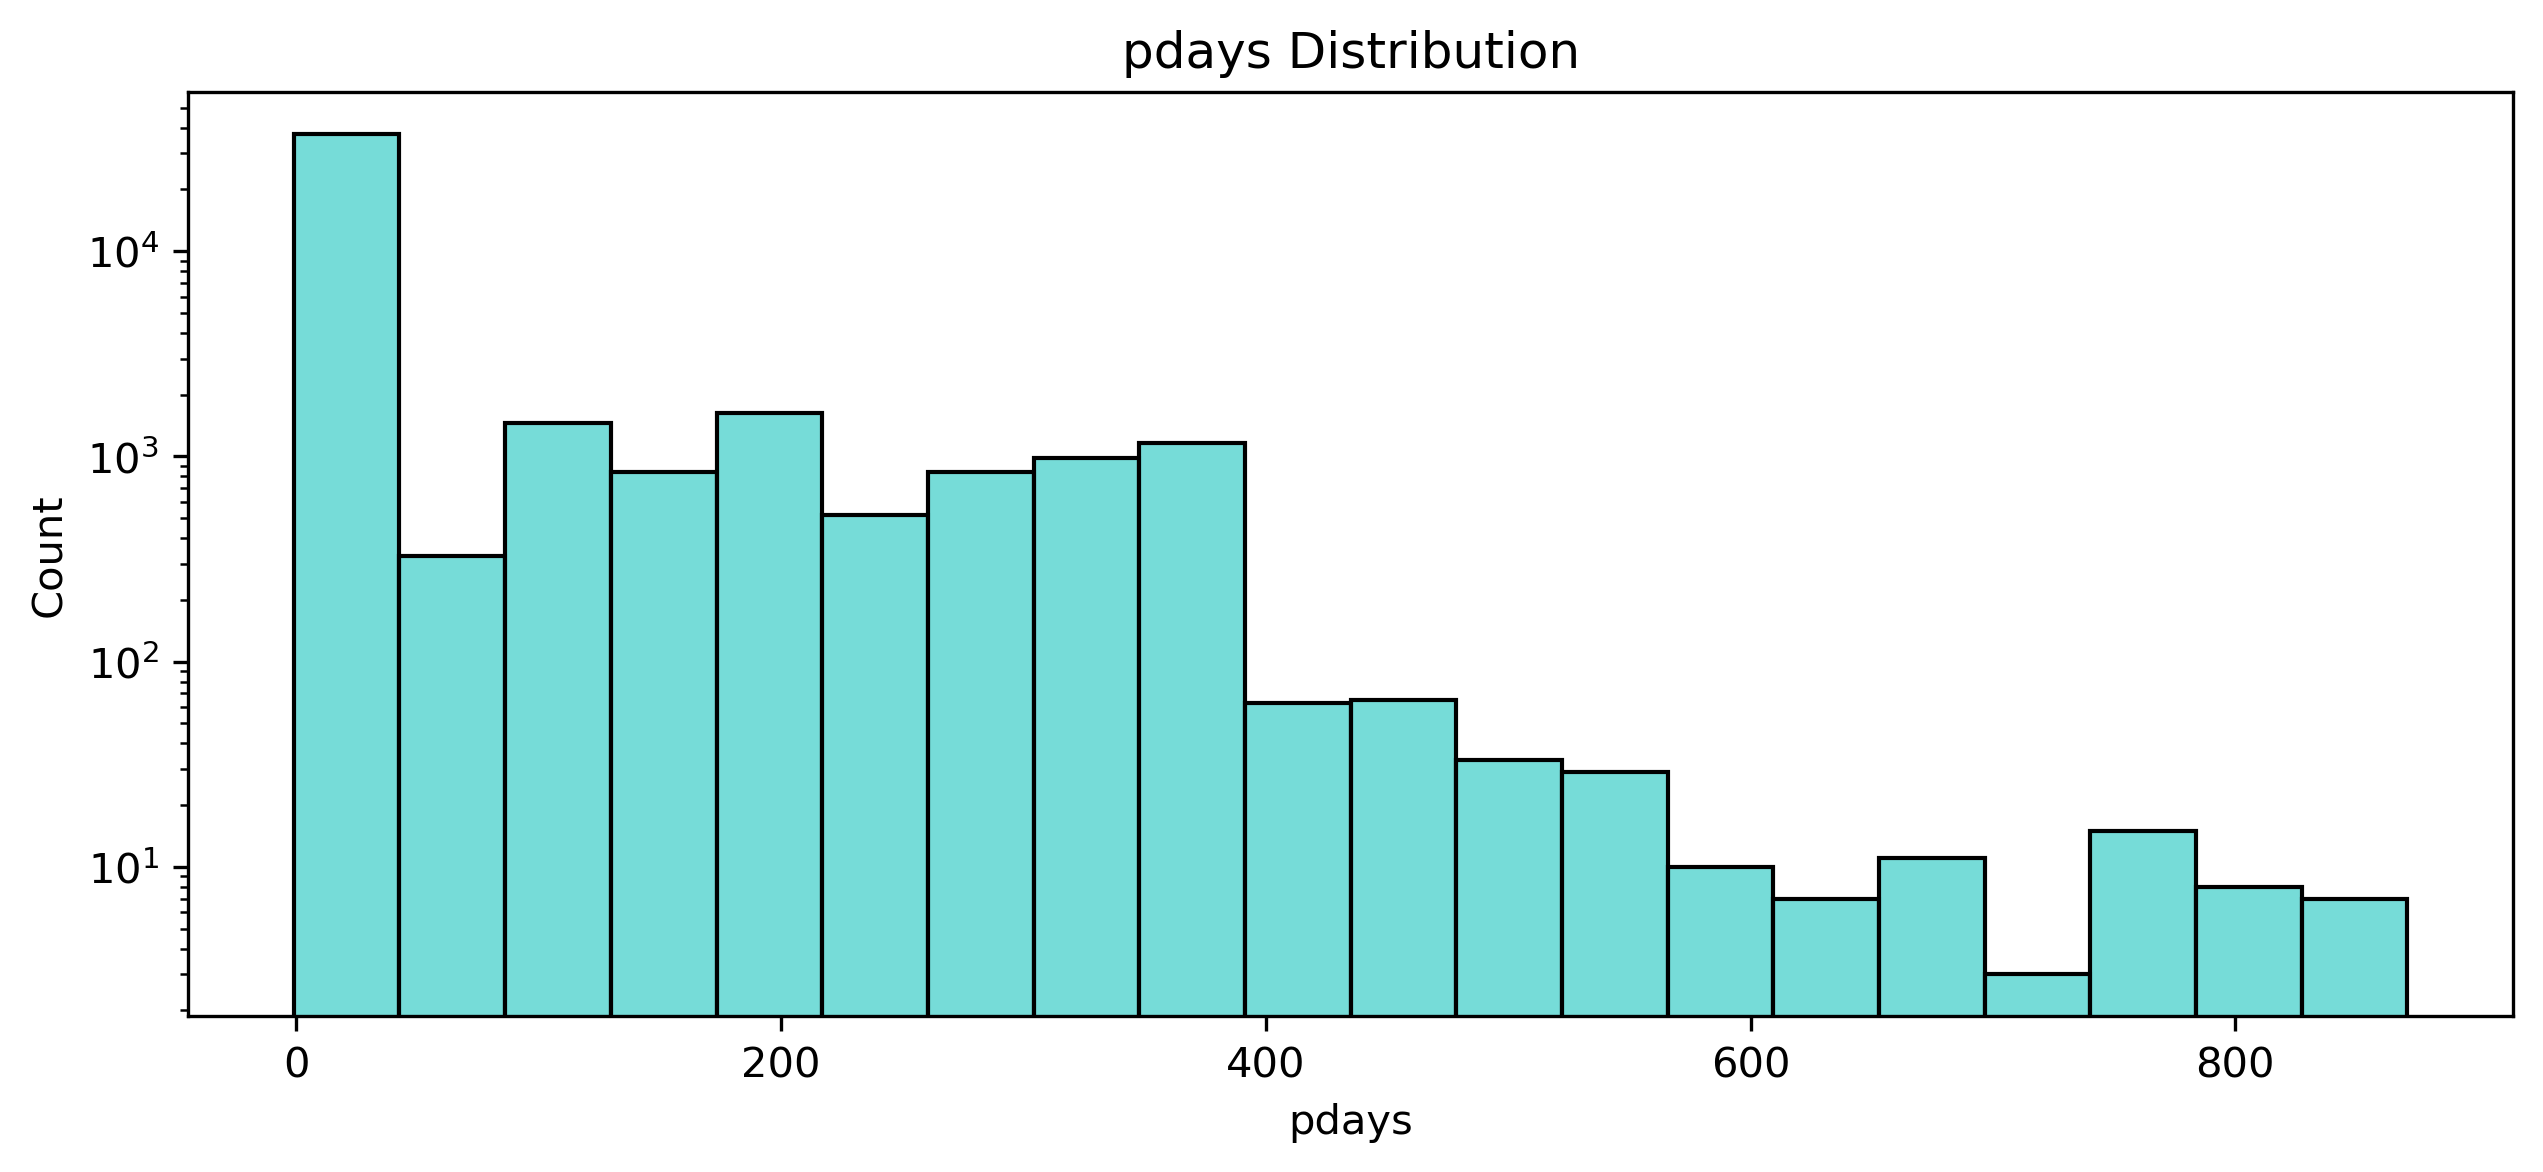

In [15]:
#PDAYS DISTRIBUTION
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'pdays', bins = 20, log = True, color = 'mediumturquoise')

plt.title('pdays Distribution')
plt.show()

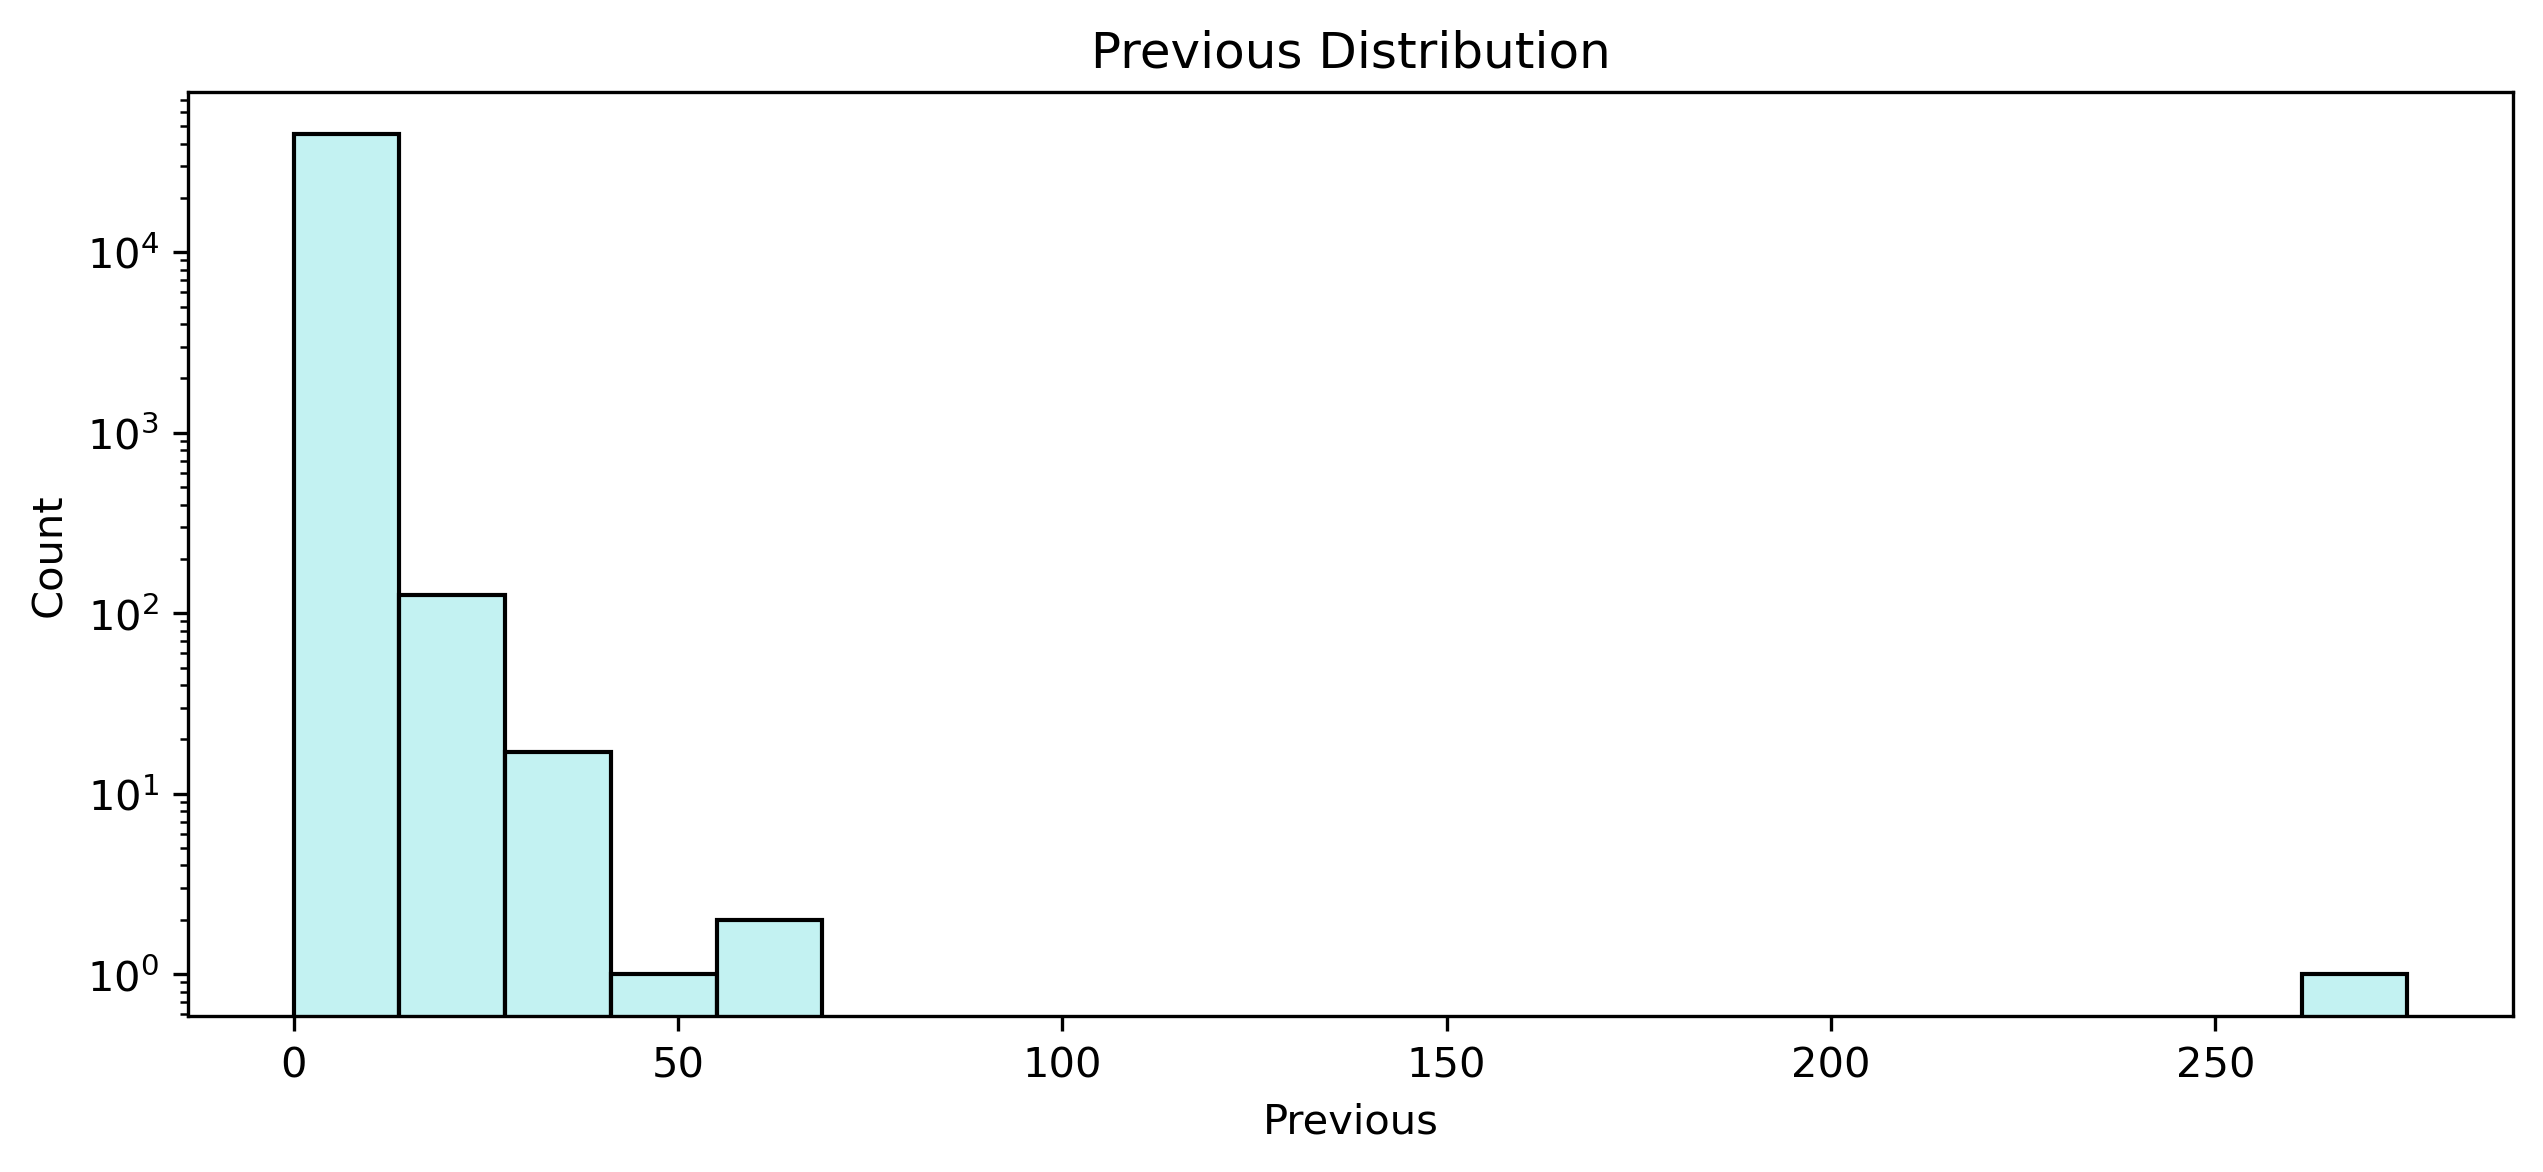

In [16]:
#PREVIOUS DISTRIBUTION
plt.figure(figsize = (10,4), dpi = 300)
sns.histplot(data = df, x = 'previous', bins = 20, log = True, color = 'paleturquoise')

plt.title('Previous Distribution')
plt.xlabel('Previous')
plt.show()

## Visualise Target Imbalance

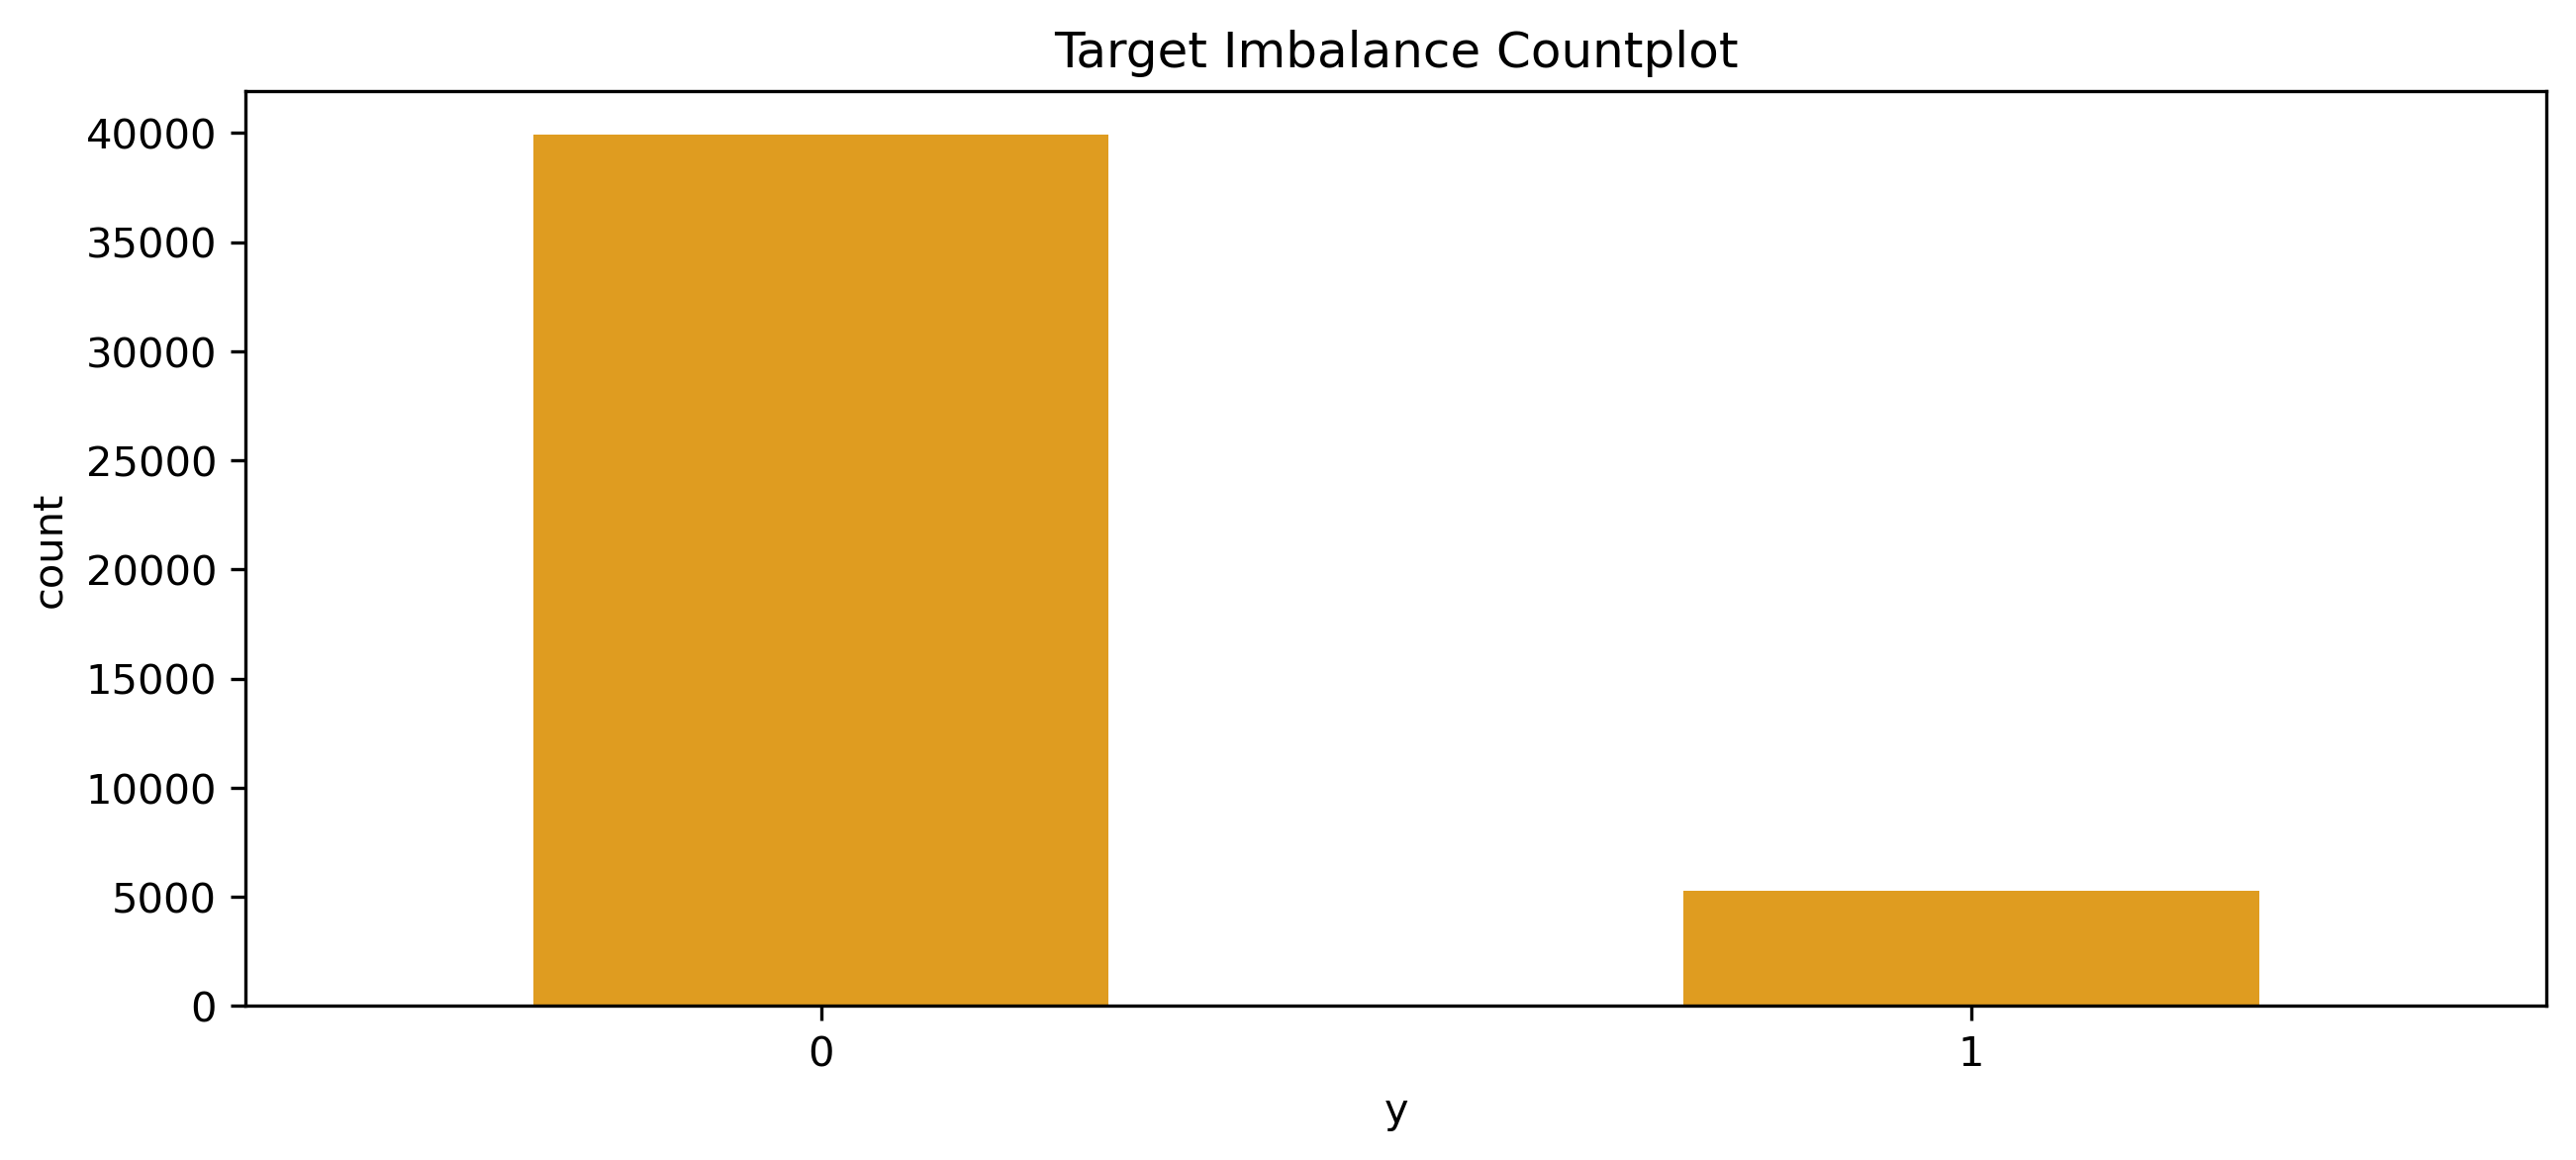

In [16]:
#TARGET IMBALANCE (y) COUNTPLOT
plt.figure(figsize = (10,4),dpi = 300)
sns.countplot(data = df, x = 'y', width = 0.5, color = 'orange')

plt.title('Target Imbalance Countplot')
plt.show()

**Commentary:**
* The target variable shows strong class imbalance - a large majority of customers fall into the "no" category and only a small minority in the "yes" category.
* As the "no" class dominates the dataset, a model trained without addressing this imbalance will predict "no" for most cases, achieving high accuracy but poor real-world performance.
* This will need to be handled during modelling.

## Categorical Variable Distribution

Text(0.5, 1.0, 'Distribution of Job Categories')

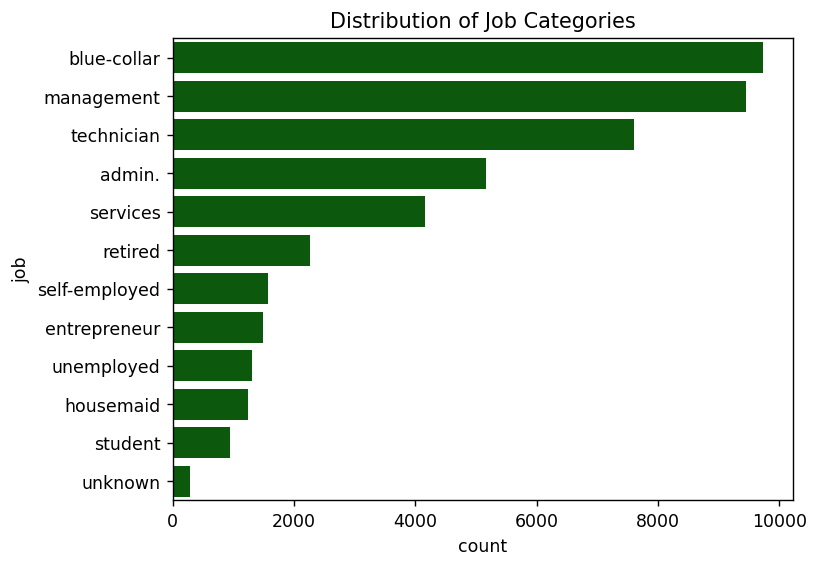

In [15]:
#JOB DISTRIBUTION
plt.figure(dpi = 125)
order = df['job'].value_counts().index
sns.countplot(data = df, y = 'job', order = order, color = 'darkgreen')

plt.title('Distribution of Job Categories')

**Commentary:**
* There is an imbalance across categories. Blue-collar, management, and technician roles makes up the largest portions of the dataset, while categories such as housemaid, student, and unknown are must smaller.
* The uneven distribution suggests that the marketing campaign ached certain occupational groups more heavily than other, which influences how jobs interacts with the target variable.
* The presence of 'unknown' also indicates missing or incomplete occupation data which may need to be handled during preprocessing.

Text(0.5, 1.0, 'Distribution of Marital Categories')

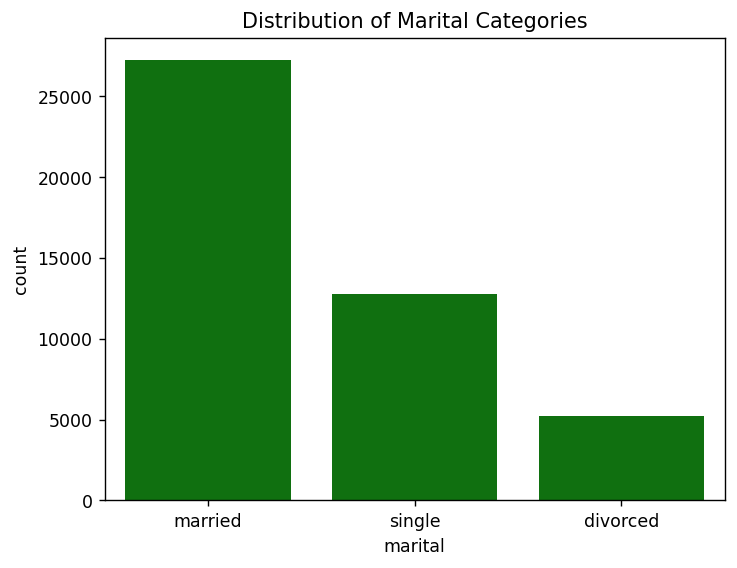

In [14]:
#MARITAL DISTRIBUTION
plt.figure(dpi = 125)
sns.countplot(data = df, x = 'marital', color = 'green')

plt.title('Distribution of Marital Categories')

**Commentary:**
* The "married" category forms the majorityof this feature, where it accounts for more than half of all customers.
* Single individuals form the second-largest group, while divorced customers represent a much smaller portion.

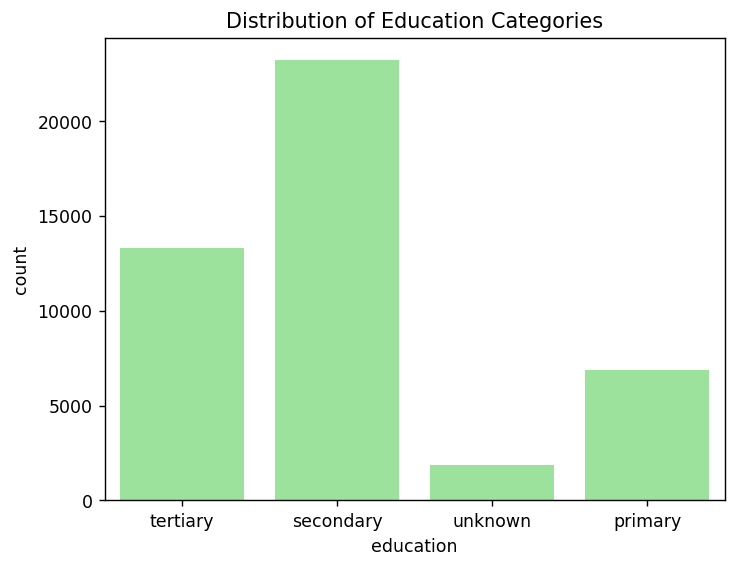

In [13]:
#EDUCATION DISTRIBUTION
plt.figure(dpi = 125)
sns.countplot(data = df, x = 'education', color = 'lightgreen')

plt.title('Distribution of Education Categories')
plt.show()

**Commentary:**
* Most customers have secondary education, followed by tertiary and then primary education.
* With most customers having a secondary education, it suggests the campaign primarily reached idividuals with mid-level educational backgrounds.
* A small "unknown" category shows missing or unreported education levels which will need to be addressed during preprocessing.

## Correlation Analysis

Text(0.5, 1.0, 'Correlation Analysis of Numeric Features')

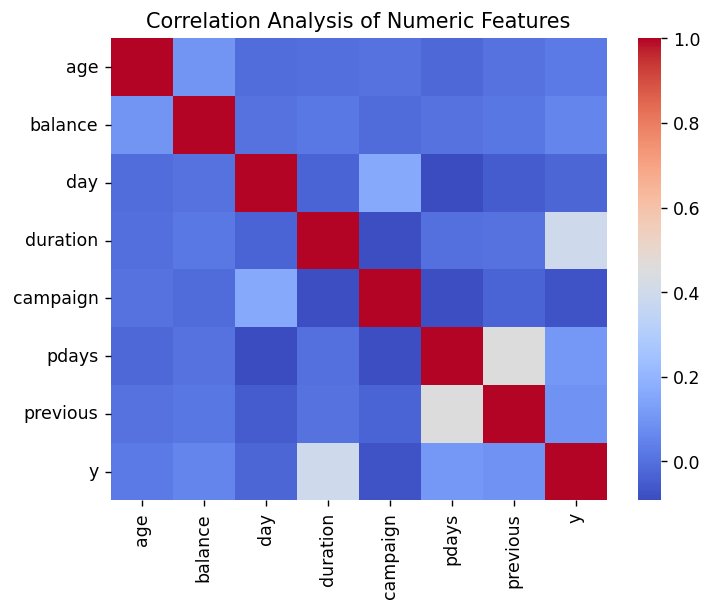

In [11]:
numeric_df = df.select_dtypes(include = ['int64'])
corr = numeric_df.corr()

plt.figure(dpi = 125)
sns.heatmap(corr, annot = False, cmap = 'coolwarm')

plt.title("Correlation Analysis of Numeric Features")

**Commentary:**
* The correlation heatmap shows that the numeric features in the dataset have weak linear relationships with one another.
* Most correlation values are close to zero, which indicates that most numeric variables behave independently.
* The only notable relationship is a moderate correlation between pdays and previous, which is expected as both relate to past contact history.
* Multicollinearity is not a concern in this dataset.

## Correlation Between Target and Numeric Variables

Text(0.5, 1.0, 'Correlation analysis: Numeric Features vs Target Variables')

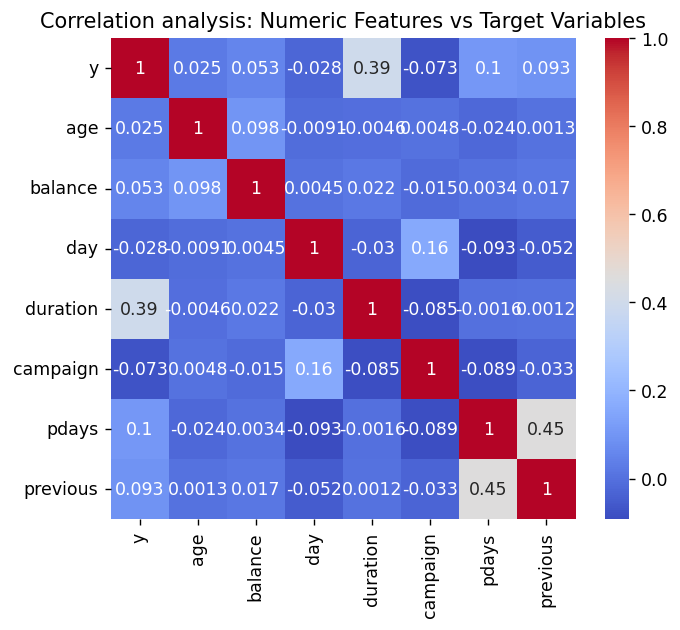

In [10]:
#Visualise Correlations with Heatmap

#Select the target and numerical variables and calculate the correlations between them
df['y'] = df['y'].replace({
    'no':0,
    'yes':1
}).infer_objects(copy = False)

num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
corr = df[['y']+num_cols].corr()

#Visualise the correlations calculated as a heatmap
plt.figure(figsize = (6,5), dpi = 125)
sns.heatmap(corr, annot = True, cmap = 'coolwarm')

#Define title
plt.title('Correlation analysis: Numeric Features vs Target Variables')

**Commentary:**
* We can see that duration and the target variable have the strongest positive correlation (coefficient of 0.39).
* This is to be expected as customers who did not subscribe are more likely to have shorter phone calls. This could be a source of leakage so needs to be investigated further.

## Relationship Between Duration and Target (Leakage Check)

Text(0.5, 1.0, 'Relationship between Duration and Target')

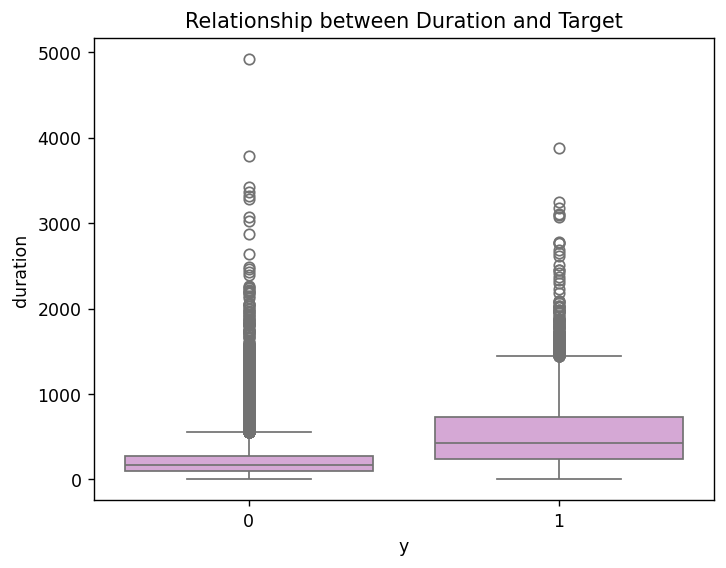

In [12]:
plt.figure(dpi = 125)
sns.boxplot(x = 'y', y = 'duration', data = df, color = 'plum')

plt.title('Relationship between Duration and Target')

**Commentary:**
* Customers who did not subscribe ("no") tend to have much shorter call durations, with only a few unusually long durations.
* However, customers who subscribed ("yes") show longer durations, with a higher median, indicating that successful calls tend to last significantly longer.
* This showsthat separation is a highly informative variable.
* However, because duration is only known after the call occurs, it represents data leakage, and may not be used as a predictive feature during modelling.

## Outlier Identification

Text(0.5, 1.0, 'Possible Age Outliers')

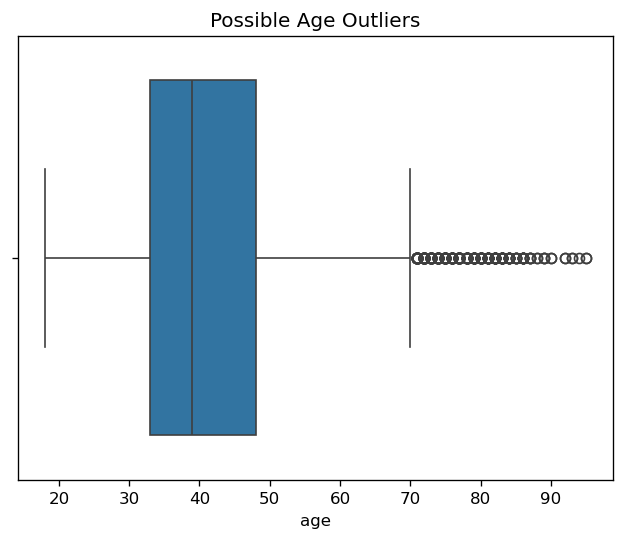

In [20]:
#AGE OUTLIERS
plt.figure(dpi = 120)
sns.boxplot(x = df['age'])

plt.title('Possible Age Outliers')

**Commentary:**
* The age boxplot shows that most customers fall between 20 and 70, with a median of just below 40 years old.
* A small number of older individuals appear as statistical outliers, but these are realistic and represent genuine variation in customer age rather than data errors.

Text(0.5, 1.0, 'Possible Balance Outliers')

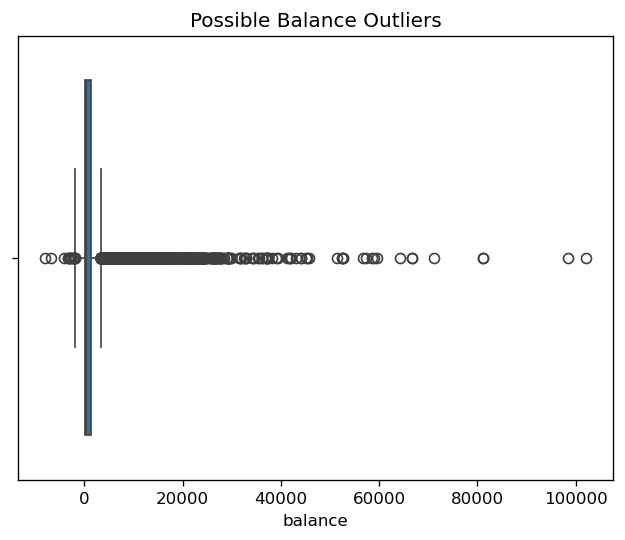

In [22]:
#BALANCE OUTLIERS
plt.figure(dpi = 120)
sns.boxplot(x = df['balance'])

plt.title('Possible Balance Outliers')

**Commentary:**
* The boxplot shows that while most customers have relatively low yearly balances, the variable contains a large number of statistical outliers extending to very high values.
* These ouliers represent customers with exceptionally large balances, reaching up to around 80,000-100,000.
* Although these fall far outside the typical range, they are realistic observations, reflecting variation in customer finances.
* Therefore, whilst the high-balance outliers reinforces the strong right-skew seen in the histogram, they do not require removal during preprocessing.

Text(0.5, 1.0, 'Possible Duration Outliers')

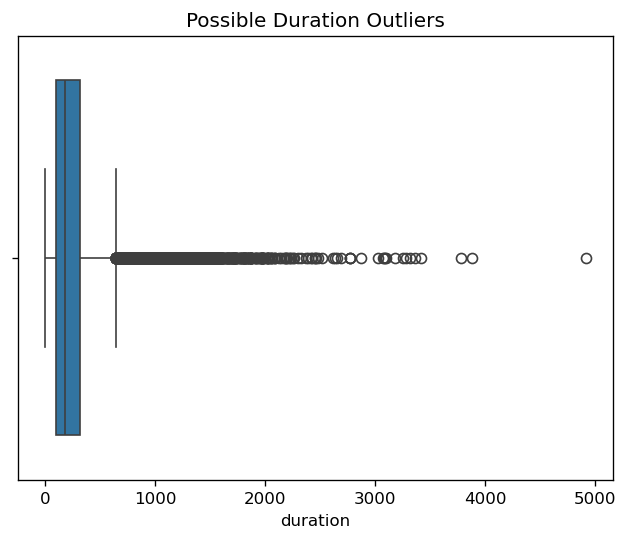

In [23]:
#DURATION OUTLIERS
plt.figure(dpi = 120)
sns.boxplot(x=df['duration'])

plt.title('Possible Duration Outliers')

**Commentary:**
* The boxplot shows that most calls are very short, with the majority of values clustered near the lower end of the scale.
* The variable contains a large number of statistical outliers, representing calls that extend up to 5,000 seconds.
* However, these seem to be genuine observations where conversations may continue for a longer time.

Text(0.5, 1.0, 'Possible Previous Outliers')

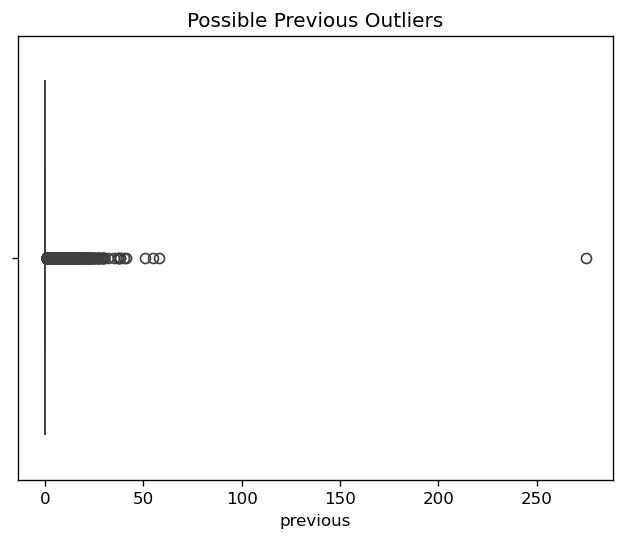

In [26]:
#PREVIOUS OUTLIERS
plt.figure(dpi = 120)
sns.boxplot(x=df['previous'])

plt.title('Possible Previous Outliers')

**Commentary:**
* The boxplot shows that there is one extreme value in the `previous` column.
* This might need to be investigated during preprocessing as it might affect the training of the model.

## Summary

* The dataset shows right-skewed numeric features with valid but extreme outliers, especially in balance and duration.
* Duration strongly separates the target classes and must be removed due to leakage.
* Categorical variables are unevenly distributed, with certain groups dominating.
* The target is highly imbalanced, requiring class-balancing strategies.
* Correlations between numeric features are weak overall.